In [1]:
# import package
import numpy as np
import pandas as pd

In [3]:
data = pd.read_csv('./Data Praktikum/dataset.csv')

In [4]:
# melihat beberapa data awal
data.head()

# mengecek ukuran data
data.shape

# informasi tentang data
data.info()

# deskripsi data
data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), str(3)
memory usage: 69.8 KB


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


In [5]:
# import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# visualisasi korelasi dengan heatmap
sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True)
plt.show()

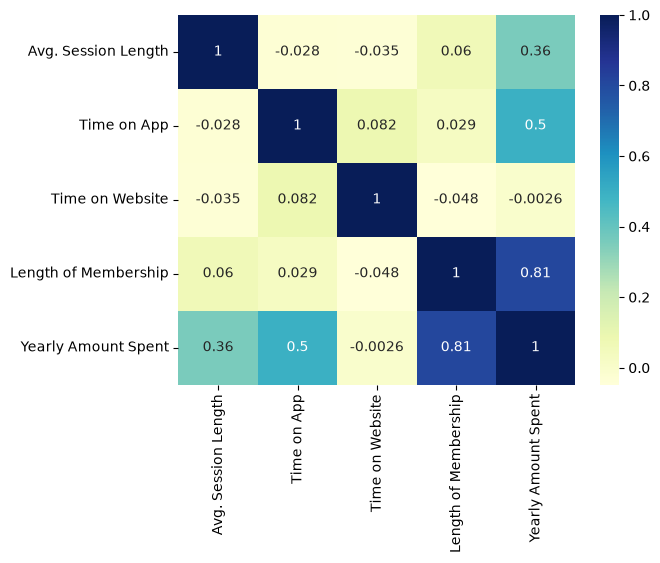

In [8]:
# visualisasi korelasi dengan heatmap
sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True)
plt.show()

In [10]:
# membuat variabel bebas x dan y, contoh pengambilan dari analisis korelasi sebelumnya
x = data['Length of Membership']
y = data['Yearly Amount Spent']

In [11]:
# pembagian data latih dan data uji dengan proporsi 7:3
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.7, test_size=0.3, random_state=100)

In [12]:
# Training model
import statsmodels.api as sm

x_train_sm = sm.add_constant(x_train)
lr = sm.OLS(y_train, x_train_sm).fit()

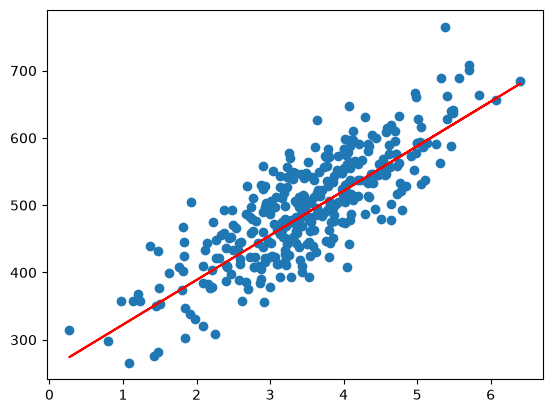

In [13]:
# visualisasi garis regresi pada data latih
plt.scatter(x_train, y_train)
plt.plot(x_train, 256.2483 + 66.3015*x_train, 'r')
plt.show()

In [20]:
# prediksi nilai y_value dari data x yang telah dilatih
y_train_pred = lr.predict(x_train_sm)

# menghitung residual
res = (y_train - y_train_pred)

C:\Users\hf\AppData\Local\Temp\ipykernel_15456\3964578609.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(res, bins=15)


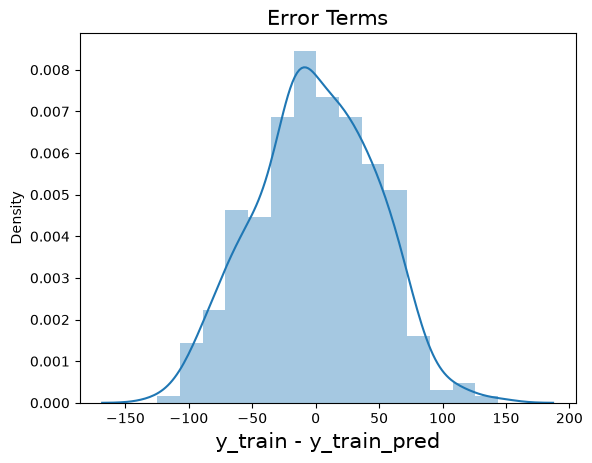

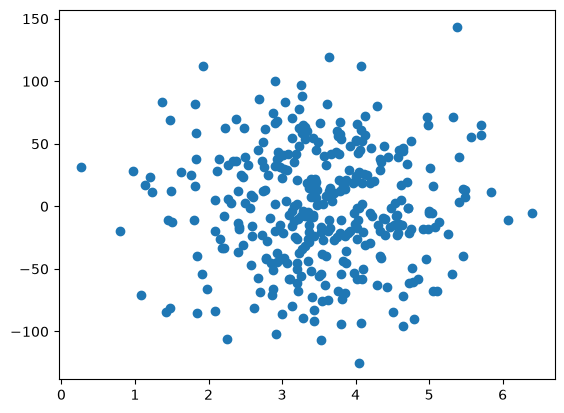

In [22]:
# Histogram residual
fig = plt.figure()
sns.distplot(res, bins=15)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

# Scatter plot residual
plt.scatter(x_train, res)
plt.show()

In [23]:
# prediksi pada data uji
x_test_sm = sm.add_constant(x_test)
y_test_pred = lr.predict(x_test_sm)

In [24]:
# hitung nilai R-squared
from sklearn.metrics import r2_score

r_squared = r2_score(y_test, y_test_pred)

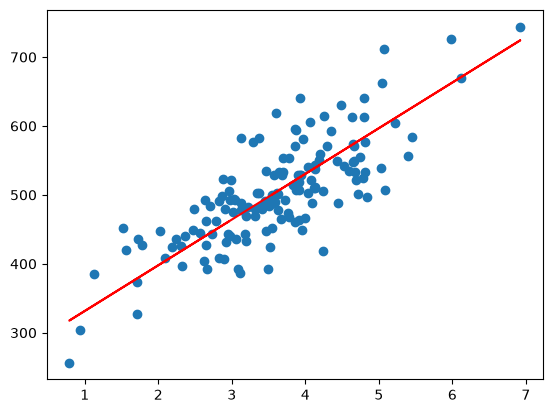

In [26]:
# visualisasi data uji dan hasil prediksi 
plt.scatter(x_test, y_test)
plt.plot(x_test, y_test_pred, 'r')
plt.show()

In [27]:
# import library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [28]:
# mengimport dataset
dataset = pd.read_csv('./Data Praktikum/Posisi_gaji.csv')
x = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values

In [29]:
# feature scalling
from sklearn.preprocessing import StandardScaler
sc_x = StandardScaler()
sc_y = StandardScaler()
x = sc_x.fit_transform(x.reshape(-1, 1))
y = sc_y.fit_transform(x.reshape(-1, 1))

In [32]:
# fitting SVR ke dataset
from sklearn.svm import SVR
regresor = SVR(kernel='rbf')
regresor.fit(x, y)

d:\Aplikasi\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


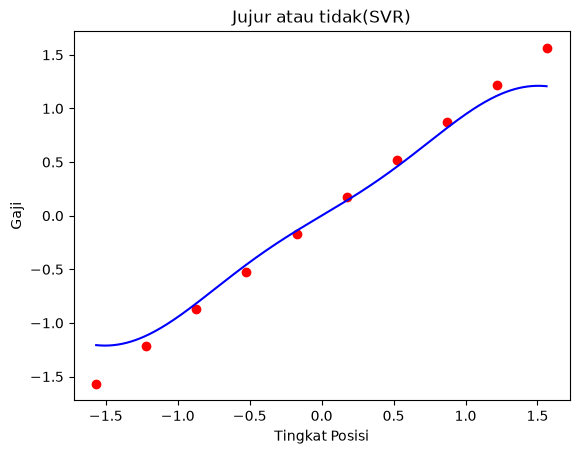

In [35]:
# visualisasi hasil SVR (resolusi tinggi dan kurva yang lebih halus)
x_grid = np.arange(x.min(), x.max(), 0.01).reshape(-1, 1)
plt.scatter(x, y, color='red')
plt.plot(x_grid, regresor.predict(x_grid), color='blue')
plt.title('Jujur atau tidak(SVR)')
plt.xlabel('Tingkat Posisi')
plt.ylabel('Gaji')
plt.show()

In [38]:
# Prediksi hasil

# Buat array 2D yang berisi tingkat posisi yang akan diprediksi
tingkat_posisi_prediksi = np.array([[6.5]])

# Penskalaan fitur untuk data yang akan diprediksi
tingkat_posisi_prediksi = sc_x.transform(tingkat_posisi_prediksi)  # Sesuaikan nama: sc_X atau sc_x

# Melakukan prediksi menggunakan model SVR
gaji_prediksi = regresor.predict(tingkat_posisi_prediksi)  # Gunakan 'regresor' bukan 'regressor'

# Kembalikan hasil prediksi ke skala aslinya
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))  # Sesuaikan: sc_y atau sc_Y

print(f"Prediksi gaji untuk tingkat posisi 6.5: ${gaji_prediksi[0][0]:,.2f}")

Prediksi gaji untuk tingkat posisi 6.5: $0.29


In [39]:
# menampilkan hasil prediksi
print('Prediksi Gaji untuk tingkat posisi 6.5:', gaji_prediksi[0])

Prediksi Gaji untuk tingkat posisi 6.5: [0.29047426]


In [40]:
# evaluasi model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y
y_pred = regresor.predict(x)

# menghitung MAE
mae = mean_absolute_error(y_actual, y_pred)

# menghitung MSE
mse = mean_squared_error(y_actual, y_pred)

# menghitung RMSE
rmse = np.sqrt(mse)

# menghitung R-squared
r2 = r2_score(y_actual, y_pred)

print('MAE: ', mae)
print('MSE: ', mse)
print('RMSE: ', rmse)
print('R-Squared: ', r2)

MAE:  0.12260683840353545
MSE:  0.029564369993530005
RMSE:  0.17194292655858223
R-Squared:  0.97043563000647
